# 02. Модель

Прогноз `salary_in_usd` по опыту, должности, стране, размеру компании и формату работы. Признаки и обучение — в `src/features.py` и `src/train.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import features as F
import train as T

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.width', 160)

## 1. Очистка

- Удаляются полные дубли (иначе одна строка попадает и в train, и в валидацию).
- Удаляются `salary` и `salary_currency` — утечка таргета.

In [2]:
raw = F.load_raw(ROOT / 'data' / 'ds_salaries.csv')
df = F.clean(raw)
print(f'Было строк: {len(raw)}, полных дублей: {len(raw) - len(df)}, осталось: {len(df)}')

# утечка: salary совпадает с salary_in_usd для выплат в USD
usd = df[df.salary_currency == 'USD']
print(f"Корреляция salary и salary_in_usd у тех, кто получает в $: {usd.salary.corr(usd.salary_in_usd):.3f}")

Было строк: 607, полных дублей: 42, осталось: 565
Корреляция salary и salary_in_usd у тех, кто получает в $: 1.000


## 2. Признаки

| Колонка | Признак |
|---|---|
| `experience_level`, `company_size` | порядковые 0…3 / 0…2 |
| `job_title` (50 значений) | `job_family` (5 групп) + `is_leadership` |
| `employee_residence`, `company_location` (59 стран) | регион US / HIGH / MID / OTHER + `same_country` |
| `employment_type` | `is_full_time` (97% — FT) |
| `remote_ratio`, `work_year` | без изменений |

Таргет — `log(salary_in_usd)`: длинный правый хвост, мультипликативные эффекты.

,experience,company_size_n,remote_ratio,work_year,is_leadership,is_full_time,same_country,job_family,residence_region,company_region
0,1,2,0,2020,0,1,1,Data Science,HIGH,HIGH
1,2,0,0,2020,0,1,1,ML/AI,HIGH,HIGH
2,2,1,50,2020,0,1,1,Data Eng,HIGH,HIGH
3,1,0,0,2020,0,1,1,Analyst,OTHER,OTHER
4,2,2,50,2020,0,1,1,ML/AI,US,US


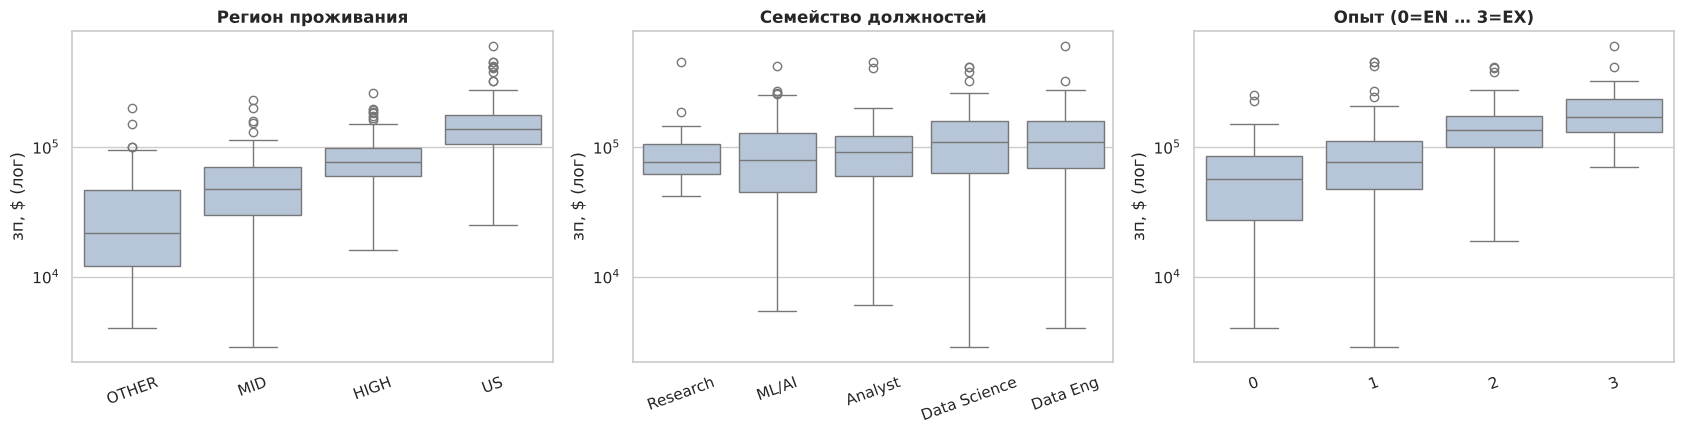

Медианная зп по регионам:
                      median  count
residence_region                   
OTHER             21,740.500     52
MID               47,590.500     74
HIGH              76,833.000    143
US               138,175.000    296


In [3]:
X, y = F.build_features(df), F.target(df)
display(X.head())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in [(axes[0], 'residence_region', 'Регион проживания'),
                       (axes[1], 'job_family', 'Семейство должностей'),
                       (axes[2], 'experience', 'Опыт (0=EN … 3=EX)')]:
    order = df.groupby(X[col])['salary_in_usd'].median().sort_values().index
    sns.boxplot(x=X[col], y=df['salary_in_usd'], order=order, ax=ax, color='lightsteelblue')
    ax.set_yscale('log'); ax.set_title(title, fontweight='bold'); ax.set_xlabel(''); ax.set_ylabel('зп, $ (лог)')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print('Медианная зп по регионам:')
print(df.groupby(X.residence_region)['salary_in_usd'].agg(['median', 'count']).sort_values('median'))

Регион разделяет зарплаты сильнее всего: US против OTHER — примерно в 6 раз, больше, чем EN против EX.

## 3. Группировка признаков против сырых one-hot колонок (Ridge)

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

raw_num = ['work_year', 'remote_ratio']
raw_cat = ['experience_level', 'employment_type', 'job_title', 'employee_residence', 'company_location', 'company_size']
raw_pipe = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), raw_num),
                                                 ('cat', OneHotEncoder(handle_unknown='ignore'), raw_cat)])),
                     ('model', Ridge(alpha=1.0))])
grp_pipe = T.make_models()['Ridge (линейная)']

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
res = {}
for name, pipe, Xs in [('сырые колонки (one-hot всего)', raw_pipe, df[raw_num + raw_cat]),
                       ('наши группировки', grp_pipe, X)]:
    s = cross_validate(pipe, Xs, y, cv=rkf, scoring=['r2', 'neg_mean_absolute_error'])
    n_feat = pipe.fit(Xs, y)[0].transform(Xs).shape[1]
    res[name] = {'признаков после кодирования': n_feat,
                 'R² (лог)': s['test_r2'].mean(),
                 'MAE (лог)': -s['test_neg_mean_absolute_error'].mean()}
pd.DataFrame(res).T

,признаков после кодирования,R² (лог),MAE (лог)
сырые колонки (one-hot всего),170.000,0.614,0.343
наши группировки,20.000,0.646,0.327


20 признаков вместо 170 при не худшем качестве.

## 4. Сравнение моделей

20% — отложенный тест. На 80% — RepeatedKFold 5×3. Метрики в долларах после `exp`: MAE, MedAE, R², доля прогнозов в пределах ±30%.

In [5]:
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
cv = T.compare_models(X_tr, y_tr)
cv

,"MAE, $","MedAE, $",R² (лог),R² ($),в пределах ±30%,"MAE std, $"
модель,,,,,,
Ridge (линейная),"31,831.328","21,207.812",0.623,0.505,0.597,"4,105.434"
Random Forest,"32,715.131","20,902.035",0.599,0.466,0.611,"3,882.878"
Gradient Boosting,"33,017.320","21,798.224",0.606,0.472,0.592,"3,630.419"
Baseline (медиана),"52,998.342","42,237.170",-0.034,-0.027,0.389,"4,808.442"


Все модели заметно лучше бейзлайна (MAE ~$53k → ~$32k); между собой различаются меньше, чем разброс по фолдам. Выбрана Ridge — проще и интерпретируема.

## 5. Проверка на отложенном тесте

,тест
"MAE, $","29,150.047"
"MedAE, $","20,331.823"
R² (лог),0.665
R² ($),0.432
в пределах ±30%,0.646


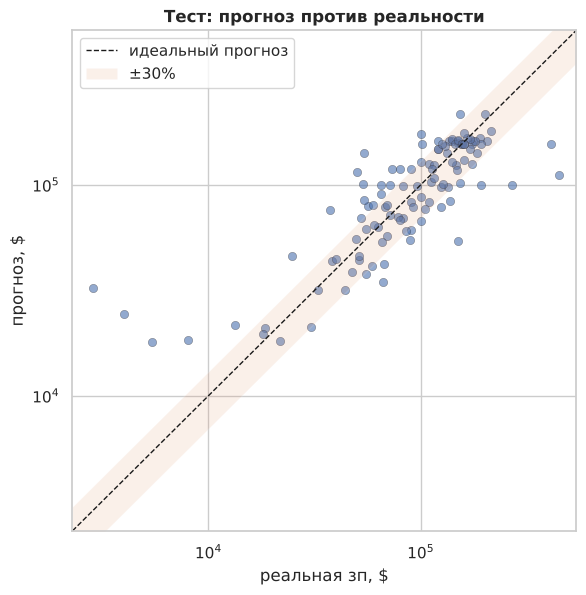

In [6]:
best = T.make_models()['Ridge (линейная)'].fit(X_tr, y_tr)
pred_te = best.predict(X_te)
test_metrics = T.dollar_metrics(y_te, pred_te)
display(pd.Series(test_metrics, name='тест').to_frame())

fig, ax = plt.subplots(figsize=(6.5, 6.5))
yt, yp = np.exp(y_te), np.exp(pred_te)
ax.scatter(yt, yp, alpha=0.6, edgecolor='k', linewidth=0.3)
lim = [min(yt.min(), yp.min()) * 0.8, max(yt.max(), yp.max()) * 1.2]
ax.plot(lim, lim, 'k--', lw=1, label='идеальный прогноз')
ax.fill_between(lim, [l * 0.7 for l in lim], [l * 1.3 for l in lim], alpha=0.12, label='±30%')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('реальная зп, $'); ax.set_ylabel('прогноз, $'); ax.legend()
ax.set_title('Тест: прогноз против реальности', fontweight='bold')
plt.show()

Тест согласуется с CV. Относительная ошибка выше на низких зарплатах (нижняя четверть — медиана ~32%, верхняя — ~13%). Крупнейшие промахи — вероятные ошибки ввода в опросе (FT, $2 859 в год).

## 6. Коэффициенты

Коэффициент `b` на лог-таргете — множитель `exp(b)`.

In [7]:
final = T.make_models()['Ridge (линейная)'].fit(X, y)
prep, ridge = final.named_steps['prep'], final.named_steps['model']
names = prep.get_feature_names_out()
coef = pd.Series(ridge.coef_, index=names)

# числовые признаки были стандартизованы: переводим эффект в «на 1 единицу признака»
scale = pd.Series(prep.named_transformers_['num'].scale_, index=['num__' + c for c in F.FEATURES_NUM])
num_eff = (coef[scale.index] / scale)
num_eff.index = [i.replace('num__', '') for i in num_eff.index]
human = {'experience': '+1 уровень опыта (EN→MI→SE→EX)', 'company_size_n': '+1 размер компании (S→M→L)',
         'remote_ratio': '+1 п.п. удалёнки', 'work_year': '+1 год (2020→2022)',
         'is_leadership': 'лид / head / director', 'is_full_time': 'полная занятость',
         'same_country': 'живёт в стране компании'}
eff = (np.exp(num_eff) - 1) * 100
eff.index = [human[i] for i in eff.index]
display(eff.sort_values().to_frame('эффект на зп, %').round(1))

# категориальные: сравниваем с базовой категорией
def cat_effect(prefix, base):
    c = coef[[i for i in coef.index if i.startswith('cat__' + prefix)]]
    c.index = [i.split('_')[-1] for i in c.index]
    return ((np.exp(c - c[base]) - 1) * 100).drop(base).sort_values()

print('Регион проживания (относительно OTHER), %:'); print(cat_effect('residence_region', 'OTHER').round(0))
print('\nСемейство должностей (относительно Analyst), %:'); print(cat_effect('job_family', 'Analyst').round(0))

,"эффект на зп, %"
живёт в стране компании,-7.500
+1 п.п. удалёнки,0.100
+1 год (2020→2022),5.000
+1 размер компании (S→M→L),12.300
+1 уровень опыта (EN→MI→SE→EX),27.400
лид / head / director,32.100
полная занятость,38.100


Регион проживания (относительно OTHER), %:
MID     39.000
HIGH   108.000
US     205.000
dtype: float64

Семейство должностей (относительно Analyst), %:
Data Eng       27.000
Data Science   31.000
ML/AI          43.000
Research       52.000
dtype: float64


Эффекты при прочих равных: опыт, регион и семейство должности — основные; размер компании ~+12% за ступень; удалёнка почти не влияет. `same_country` отрицателен: работающие из другой страны — обычно удалённые сотрудники зарубежных (чаще американских) компаний.

## 7. Где модель ошибается

In [8]:
from sklearn.model_selection import cross_val_predict, KFold
oof = cross_val_predict(T.make_models()['Ridge (линейная)'], X, y, cv=KFold(5, shuffle=True, random_state=42))
err = pd.DataFrame({'region': X.residence_region, 'experience': df.experience_level,
                    'abs_pct_err': np.abs(np.exp(oof) / np.exp(y) - 1) * 100})
display(err.groupby('region')['abs_pct_err'].agg(['median', 'count']).round(1).rename(columns={'median': 'медианная ошибка, %'}))
display(err.groupby('experience')['abs_pct_err'].agg(['median', 'count']).round(1).rename(columns={'median': 'медианная ошибка, %'}))

,"медианная ошибка, %",count
region,,
HIGH,23.600,143
MID,35.200,74
OTHER,38.700,52
US,20.400,296


,"медианная ошибка, %",count
experience,,
EN,29.100,88
EX,20.200,26
MI,25.400,208
SE,19.600,243


Ошибка выше в регионах MID и OTHER: мало данных и неоднородные страны внутри группы.

## 8. Интервал прогноза

10-й и 90-й перцентили out-of-fold остатков → 80%-интервал.

In [9]:
resid = y - oof
lo, hi = np.exp(np.quantile(resid, [0.10, 0.90]))
print(f'80%-интервал: от прогноз × {lo:.2f} до прогноз × {hi:.2f}')
example = pd.DataFrame([{'work_year': 2022, 'experience_level': 'SE', 'employment_type': 'FT',
                         'job_title': 'Data Scientist', 'employee_residence': 'DE', 'remote_ratio': 100,
                         'company_location': 'DE', 'company_size': 'M'}])
p = float(np.exp(final.predict(F.build_features(example)))[0])
print(f'Пример: Senior Data Scientist, Германия, удалёнка, средняя компания → ${p:,.0f} (80%: ${p*lo:,.0f} – ${p*hi:,.0f})')

80%-интервал: от прогноз × 0.64 до прогноз × 1.61
Пример: Senior Data Scientist, Германия, удалёнка, средняя компания → $99,668 (80%: $63,476 – $160,887)


## 9. Сохранение

`src/train.py` воспроизводит обучение и сохраняет модель на всех данных в `models/salary_model.joblib` для `app.py`.

In [10]:
T.main()

Строк после удаления дублей: 565 (train 452, test 113)

Кросс-валидация на train (5 фолдов × 3 повтора):


                       MAE, $   MedAE, $  R² (лог)  R² ($)  в пределах ±30%  MAE std, $
модель                                                                                 
Ridge (линейная)   31,831.328 21,207.812     0.623   0.505            0.597   4,105.434
Random Forest      32,715.131 20,902.035     0.599   0.466            0.611   3,882.878
Gradient Boosting  33,017.320 21,798.224     0.606   0.472            0.592   3,630.419
Baseline (медиана) 52,998.342 42,237.170    -0.034  -0.027            0.389   4,808.442 

Лучшая модель: Ridge (линейная). Результат на отложенном тесте:
   MAE, $           29,150.047
   MedAE, $         20,331.823
   R² (лог)         0.665
   R² ($)           0.432
   в пределах ±30%  0.646

Интервал 80%: прогноз × [0.64; 1.61]
Модель сохранена: /home/claude/salary_prediction/models/salary_model.joblib


## Итоги

| | |
|---|---|
| Модель | Ridge на log-таргете, 10 признаков |
| Тест | MAE ≈ $29k, 2/3 прогнозов в пределах ±30% |
| Факторы | регион ≫ опыт > семейство должности > лидерская роль |

Ограничения: 565 строк за 2020–2022, больше половины — США; по MID/OTHER данных мало; данные опросные.